<a href="https://colab.research.google.com/github/anishsikdar1102-glitch/anish-sikdar-projects/blob/main/exp%2010-Cyberbullying_Detection_in_Social_Media.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

# Direct URLs to download raw CSV files from the dataset repository
TRAIN_DATA_URL = "https://huggingface.co/datasets/sahinurlaskar/MC-Hinglish1.0/resolve/main/Train_data_MC-Hinglish1.0.csv"

# Set these after reviewing the printed dataset fields.
TEXT_COLUMN = "tweets"
LABEL_COLUMN = "cyberbullying_type"


def main():
    print("Loading dataset directly from Hugging Face repository...")
    df = pd.read_csv(TRAIN_DATA_URL)

    print("Dataset shape:", df.shape)
    print("Columns:", list(df.columns))
    print("\nSample records:")
    print(df.head())

    if TEXT_COLUMN is None or LABEL_COLUMN is None:
        print(
            "\nSet TEXT_COLUMN and LABEL_COLUMN in the script to the correct "
            "column names shown above, then run it again."
        )
        return

    if TEXT_COLUMN not in df.columns or LABEL_COLUMN not in df.columns:
        raise ValueError(
            f"Check column names. Available columns: {list(df.columns)}"
        )

    data = df[[TEXT_COLUMN, LABEL_COLUMN]].dropna().copy()
    data[TEXT_COLUMN] = data[TEXT_COLUMN].astype(str).str.strip()
    data[LABEL_COLUMN] = data[LABEL_COLUMN].astype(str)
    data = data[data[TEXT_COLUMN] != ""]
    data = data.drop_duplicates(subset=[TEXT_COLUMN, LABEL_COLUMN])

    print("\nCategory counts:")
    print(data[LABEL_COLUMN].value_counts())

    X_train, X_test, y_train, y_test = train_test_split(
        data[TEXT_COLUMN],
        data[LABEL_COLUMN],
        test_size=0.2,
        random_state=42,
        stratify=data[LABEL_COLUMN],
    )

    models = {
        "Naive Bayes": MultinomialNB(),
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
        ),
        "Linear SVM": LinearSVC(
            class_weight="balanced",
            random_state=42,
        ),
    }

    results = []
    output_dir = "results"

    for model_name, model in models.items():
        classifier = Pipeline([
            (
                "tfidf",
                TfidfVectorizer(
                    lowercase=True,
                    ngram_range=(1, 2),
                    max_features=30000,
                    strip_accents=None,
                ),
            ),
            ("model", model),
        ])

        classifier.fit(X_train, y_train)
        predictions = classifier.predict(X_test)

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_test,
            predictions,
            average="macro",
            zero_division=0,
        )

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": f1,
        })

        print(f"\n{model_name}")
        print(classification_report(y_test, predictions, zero_division=0))

        labels = sorted(y_test.unique())
        matrix = confusion_matrix(y_test, predictions, labels=labels)

        plt.figure(figsize=(8, 6))
        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=labels,
            yticklabels=labels,
        )
        plt.title(f"Confusion Matrix — {model_name}")
        plt.xlabel("Predicted label")
        plt.ylabel("Actual label")
        plt.tight_layout()
        plt.savefig(
            f"{output_dir}_{model_name.lower().replace(' ', '_')}_confusion_matrix.png",
            dpi=150,
        )
        plt.close()

    results_df = pd.DataFrame(results).sort_values(
        "Macro F1",
        ascending=False,
    )
    results_df.to_csv("model_comparison.csv", index=False)

    print("\nModel comparison:")
    print(results_df.to_string(index=False))
    print("\nSaved results to model_comparison.csv and confusion-matrix images.")


if __name__ == "__main__":
    main()

Loading dataset directly from Hugging Face repository...
Dataset shape: (7400, 2)
Columns: ['tweets', 'cyberbullying_type']

Sample records:
                                  tweets cyberbullying_type
0                      Foundation X Aata            mockery
1                    Foundation X Cement            mockery
2              Chunna laga diya got real          offensive
3  Didi show off krri h "Left hand rule"             gender
4      Matak ke chalungi X Matka chalega          offensive

Category counts:
cyberbullying_type
not_cyberbullying    1489
gender               1003
abusive               989
mockery               980
offensive             977
religion              977
age                   976
Name: count, dtype: int64

Naive Bayes
                   precision    recall  f1-score   support

          abusive       0.52      0.69      0.60       198
              age       0.88      0.81      0.84       195
           gender       0.81      0.57      0.67       201
    

### Step 1: Data Loading & Initial Exploration
We load the Hinglish cyberbullying dataset directly from Hugging Face and examine its structure.

In [11]:
import pandas as pd

TRAIN_DATA_URL = "https://huggingface.co/datasets/sahinurlaskar/MC-Hinglish1.0/resolve/main/Train_data_MC-Hinglish1.0.csv"

print("Loading dataset...")
df = pd.read_csv(TRAIN_DATA_URL)

print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())

Loading dataset...
Dataset shape: (7400, 2)
Columns: ['tweets', 'cyberbullying_type']


,tweets,cyberbullying_type
0,Foundation X Aata,mockery
1,Foundation X Cement,mockery
2,Chunna laga diya got real,offensive
3,"Didi show off krri h ""Left hand rule""",gender
4,Matak ke chalungi X Matka chalega,offensive


### Step 2: Data Preprocessing & Train-Test Split
We clean the data by dropping duplicates, stripping whitespace, and splitting it into stratified training and testing sets.

In [12]:
from sklearn.model_selection import train_test_split

TEXT_COLUMN = "tweets"
LABEL_COLUMN = "cyberbullying_type"

# Clean the data
data = df[[TEXT_COLUMN, LABEL_COLUMN]].dropna().copy()
data[TEXT_COLUMN] = data[TEXT_COLUMN].astype(str).str.strip()
data[LABEL_COLUMN] = data[LABEL_COLUMN].astype(str)
data = data[data[TEXT_COLUMN] != ""]
data = data.drop_duplicates(subset=[TEXT_COLUMN, LABEL_COLUMN])

print("Category counts:")
print(data[LABEL_COLUMN].value_counts())

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    data[TEXT_COLUMN],
    data[LABEL_COLUMN],
    test_size=0.2,
    random_state=42,
    stratify=data[LABEL_COLUMN],
)

Category counts:
cyberbullying_type
not_cyberbullying    1489
gender               1003
abusive               989
mockery               980
offensive             977
religion              977
age                   976
Name: count, dtype: int64


### Step 3: Model Pipeline Training and Evaluation
We define our TF-IDF vectorization and classifier pipelines (Naive Bayes, Logistic Regression, and Linear SVM) and evaluate their performance.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=42),
}

results = []
confusion_matrices = {}

for model_name, model in models.items():
    classifier = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                max_features=30000,
                strip_accents=None,
            ),
        ),
        ("model", model),
    ])

    # Train and predict
    classifier.fit(X_train, y_train)
    predictions = classifier.predict(X_test)

    # Metrics calculation
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions, average="macro", zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
    })

    print(f"\n=== {model_name} Classification Report ===")
    print(classification_report(y_test, predictions, zero_division=0))

    # Save the raw matrix data for visualization in the next cell
    labels = sorted(y_test.unique())
    confusion_matrices[model_name] = (confusion_matrix(y_test, predictions, labels=labels), labels)

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
results_df.to_csv("model_comparison.csv", index=False)

print("\n=== Model Comparison Table ===")
display(results_df)


=== Naive Bayes Classification Report ===
                   precision    recall  f1-score   support

          abusive       0.52      0.69      0.60       198
              age       0.88      0.81      0.84       195
           gender       0.81      0.57      0.67       201
          mockery       0.69      0.62      0.65       196
not_cyberbullying       0.61      0.93      0.74       298
        offensive       0.82      0.43      0.56       196
         religion       0.88      0.76      0.82       195

         accuracy                           0.70      1479
        macro avg       0.75      0.69      0.70      1479
     weighted avg       0.74      0.70      0.70      1479


=== Logistic Regression Classification Report ===
                   precision    recall  f1-score   support

          abusive       0.62      0.72      0.67       198
              age       0.94      0.85      0.89       195
           gender       0.81      0.71      0.76       201
          mockery

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
2,Linear SVM,0.804598,0.804152,0.799096,0.800905
1,Logistic Regression,0.762001,0.770054,0.756900,0.761038
0,Naive Bayes,0.702502,0.745296,0.686252,0.696598


### Step 4: Confusion Matrix Visualizations
Finally, we visualize and compare the confusion matrices of all three models side-by-side.

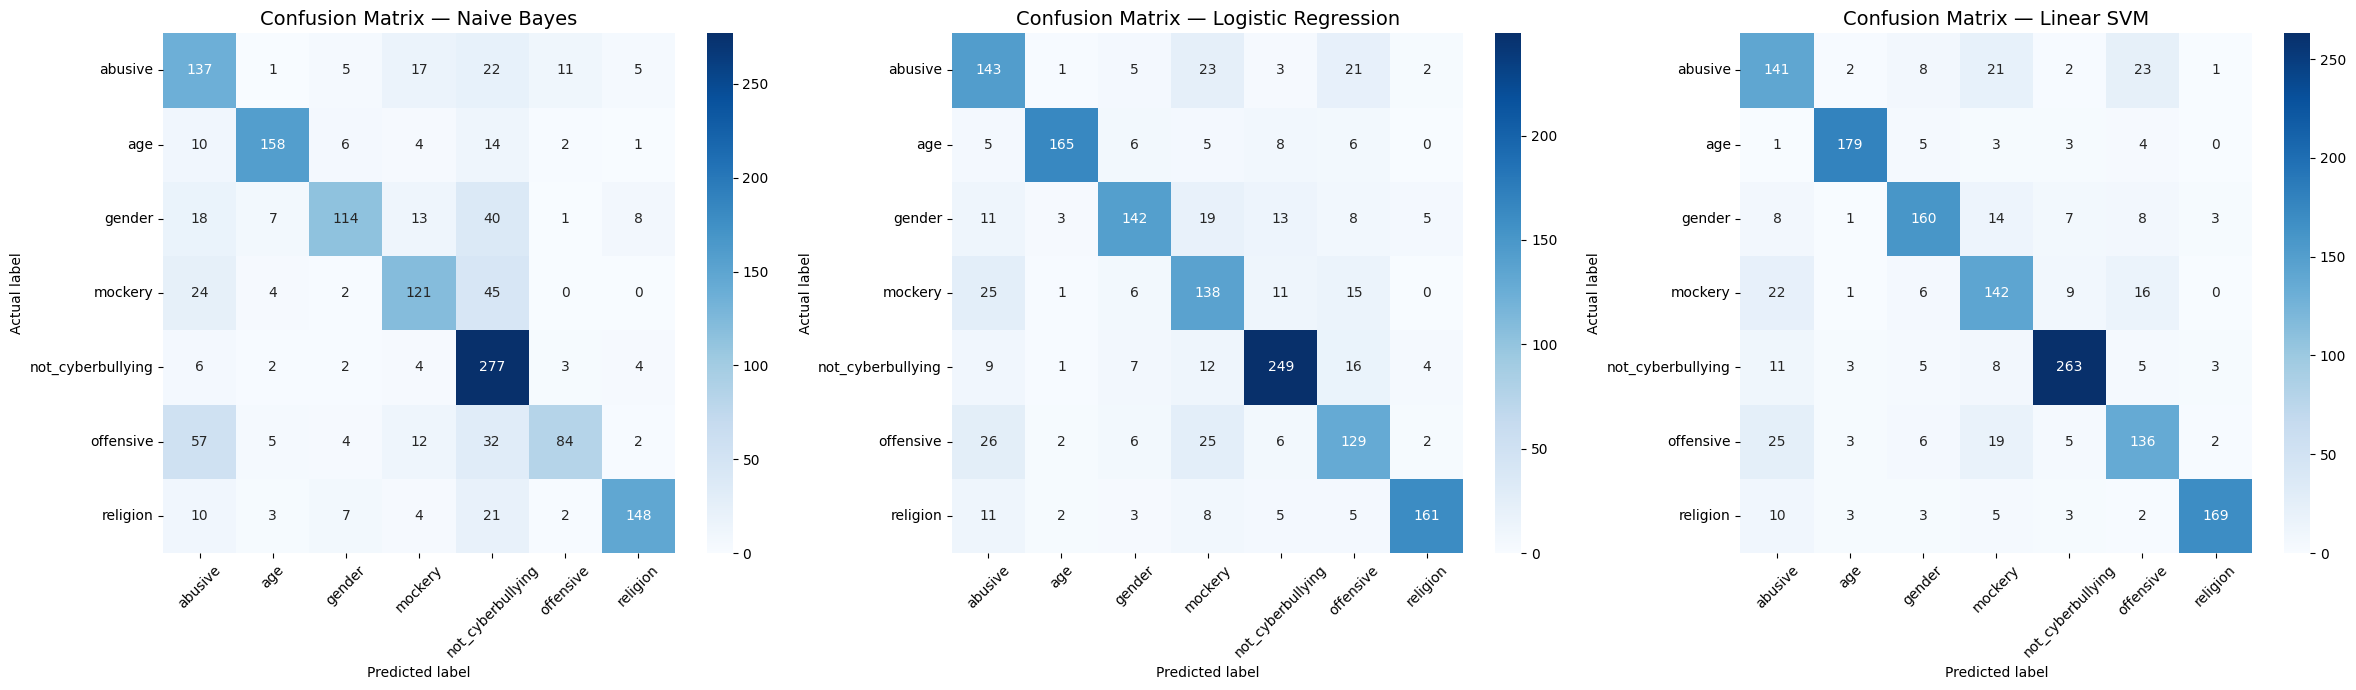

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (model_name, (matrix, labels)) in zip(axes, confusion_matrices.items()):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )
    ax.set_title(f"Confusion Matrix — {model_name}", fontsize=14)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

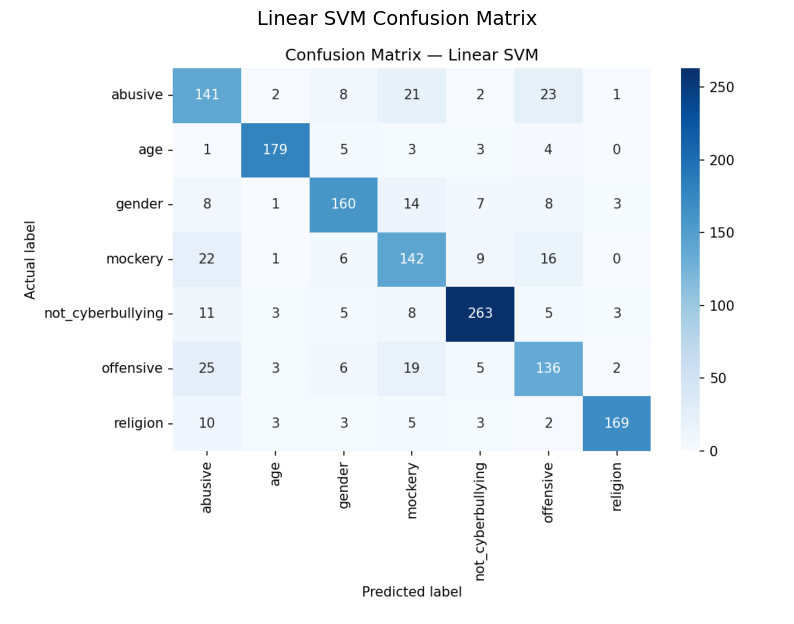

In [14]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Path to the saved Linear SVM confusion matrix
image_path = 'results_linear_svm_confusion_matrix.png'

try:
    img = mpimg.imread(image_path)
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Linear SVM Confusion Matrix', fontsize=14)
    plt.show()
except FileNotFoundError:
    print(f"Error: The file {image_path} was not found. Please make sure the classification model cell has run successfully first.")

### Step 5: Test Set Evaluation
We load the shared test dataset (`Test_data_MC-Hinglish1.0.csv`), preprocess it, and evaluate our trained Linear SVM pipeline on it to get final performance metrics.

In [16]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score

# 1. Load test CSV
test_df = pd.read_csv('/content/Test_data_MC-Hinglish1.0.csv')
print("Test dataset shape:", test_df.shape)
print("Test columns:", list(test_df.columns))

# 2. Preprocess test data
test_data = test_df[[TEXT_COLUMN, LABEL_COLUMN]].dropna().copy()
test_data[TEXT_COLUMN] = test_data[TEXT_COLUMN].astype(str).str.strip()
test_data[LABEL_COLUMN] = test_data[LABEL_COLUMN].astype(str)
test_data = test_data[test_data[TEXT_COLUMN] != ""]

X_test_final = test_data[TEXT_COLUMN]
y_test_final = test_data[LABEL_COLUMN]

# 3. Retrain the best model (Linear SVM) on full train split
best_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=30000,
            strip_accents=None,
        ),
    ),
    ("model", LinearSVC(class_weight="balanced", random_state=42)),
])

best_pipeline.fit(X_train, y_train)

# 4. Predict on the local test set
test_predictions = best_pipeline.predict(X_test_final)

# 5. Output metrics
print("\n=== Final Test Evaluation (Linear SVM) ===")
print(classification_report(y_test_final, test_predictions, zero_division=0))
print(f"Accuracy on Test Dataset: {accuracy_score(y_test_final, test_predictions):.4f}")

Test dataset shape: (1000, 2)
Test columns: ['tweets', 'cyberbullying_type']

=== Final Test Evaluation (Linear SVM) ===
                   precision    recall  f1-score   support

          abusive       0.67      0.48      0.56       148
              age       0.79      0.84      0.81       129
           gender       0.71      0.81      0.76       141
          mockery       0.42      0.35      0.38       127
not_cyberbullying       0.72      0.84      0.78       200
        offensive       0.61      0.60      0.61       124
         religion       0.78      0.80      0.79       131

         accuracy                           0.69      1000
        macro avg       0.67      0.67      0.67      1000
     weighted avg       0.68      0.69      0.68      1000

Accuracy on Test Dataset: 0.6860


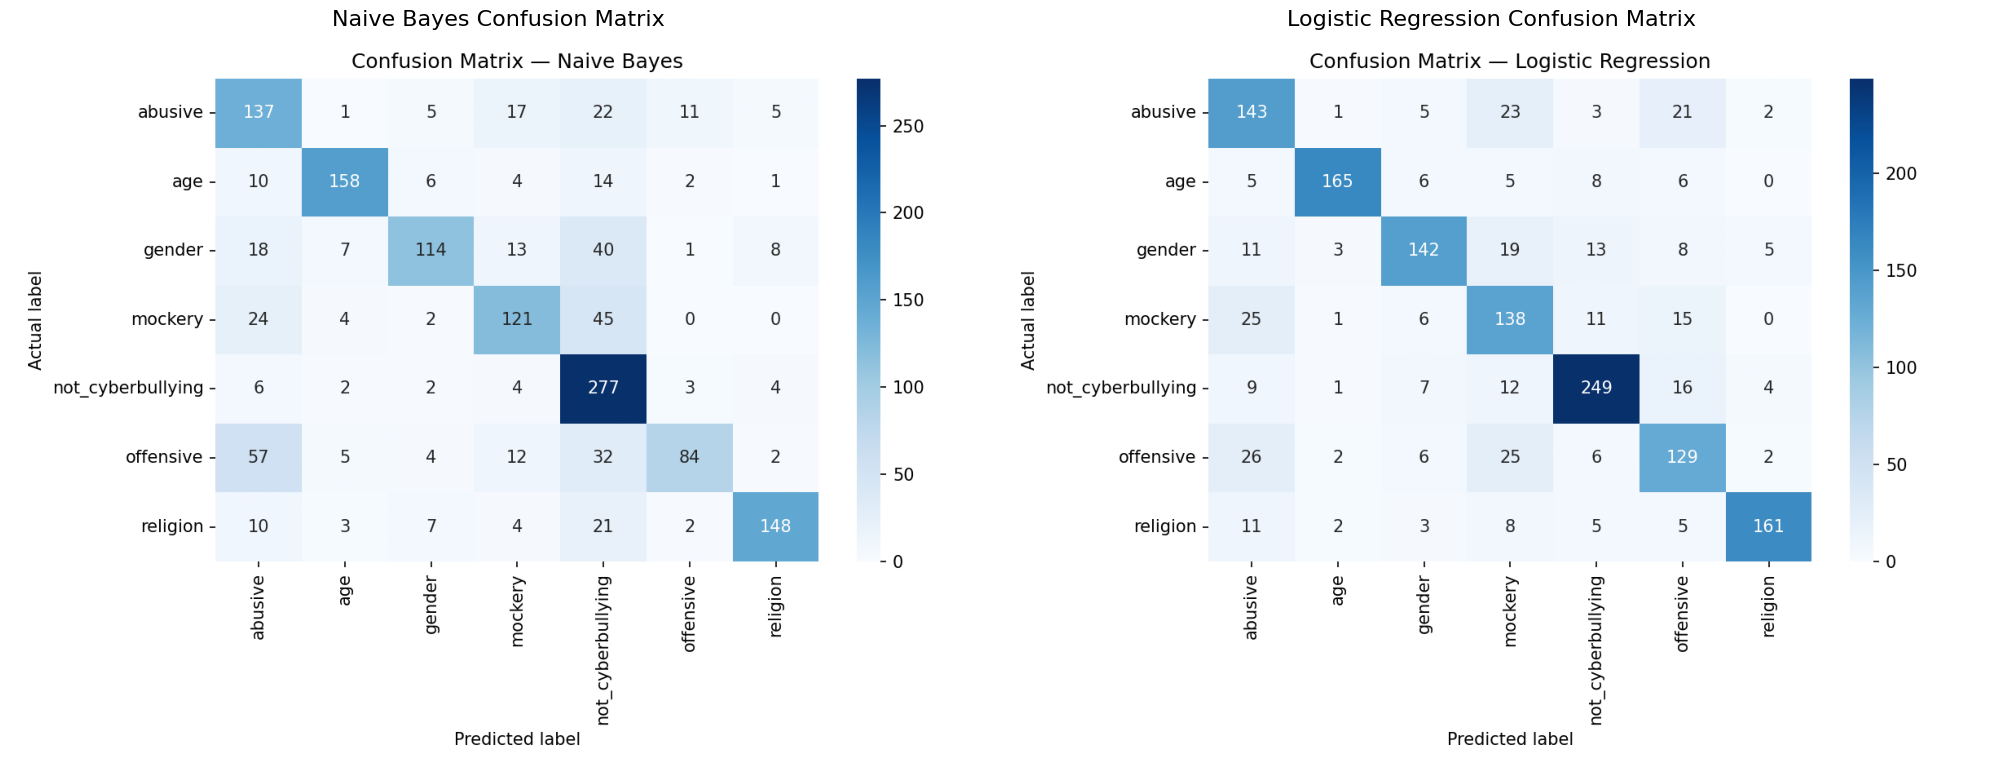

In [15]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Paths to the saved confusion matrices
nb_path = 'results_naive_bayes_confusion_matrix.png'
lr_path = 'results_logistic_regression_confusion_matrix.png'

try:
    nb_img = mpimg.imread(nb_path)
    lr_img = mpimg.imread(lr_path)

    fig, axes = plt.subplots(1, 2, figsize=(20, 10))

    axes[0].imshow(nb_img)
    axes[0].axis('off')
    axes[0].set_title('Naive Bayes Confusion Matrix', fontsize=16)

    axes[1].imshow(lr_img)
    axes[1].axis('off')
    axes[1].set_title('Logistic Regression Confusion Matrix', fontsize=16)

    plt.tight_layout()
    plt.show()
except FileNotFoundError as e:
    print(f"Error loading images: {e}. Please ensure the classification script ran successfully and generated the files.")